*  DSC630-T303 Predictive Analytics (2267-1)
*  8.2 Assignment: Time Series Modeling
*  David Jorgensen

# 8.2 Assignment: Time Series Modeling

In [1]:
# Import libraries for data handling, time series modeling, evaluation,
# and plotting.
import pandas as pd
import numpy as np
import itertools
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from statsmodels.tsa.statespace.sarimax import SARIMAX      # SARIMA modeling
from statsmodels.tsa.seasonal import seasonal_decompose      # trend/season split
from statsmodels.tsa.stattools import adfuller               # stationarity test
from statsmodels.stats.diagnostic import acorr_ljungbox      # residual test
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error               # RMSE component

# Model fitting prints convergence chatter that clutters the notebook; the
# fits themselves are checked explicitly with diagnostics further down.
warnings.filterwarnings("ignore")

# Make plots render inline and use a clean style.
%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")

## Step 1: Load the data and reshape it into a monthly time series

The raw file is stored in a *wide* layout: one row per year and one column per
month (`JAN` ... `DEC`). Time series models need a *long* layout instead, as 
a single ordered column of sales indexed by date. The steps below melt the
month columns into rows, build a proper datetime index from the year/month
pair, and set a monthly frequency so statsmodels knows the spacing between
observations.

The 2021 row is only filled through June, so the empty months at the end of
that row are dropped rather than treated as zero-sales months.

In [2]:
# Load the raw wide-format file (one row per year, one column per month).
raw = pd.read_csv("data/us_retail_sales.csv")

print("Raw shape (rows, columns):", raw.shape)
raw.head()

Raw shape (rows, columns): (30, 13)


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


In [3]:
# Melt the twelve month columns into rows so each record is one month.
long = raw.melt(id_vars="YEAR", var_name="MONTH", value_name="SALES")

# Map the month abbreviations used as column headers to month numbers.
month_num = {m: i + 1 for i, m in enumerate(
    ["JAN", "FEB", "MAR", "APR", "MAY", "JUN",
     "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"])}

# Build a datetime index from the year/month pair (first of each month).
long["DATE"] = pd.to_datetime(dict(year=long["YEAR"],
                                   month=long["MONTH"].map(month_num),
                                   day=1))

# 2021 only has data through June, so the trailing blank months are dropped.
long = long.dropna(subset=["SALES"]).sort_values("DATE").set_index("DATE")

# Extract the sales column as a monthly-frequency Series ("MS" = month start).
sales = long["SALES"].astype(float).asfreq("MS")

print("Observations:", len(sales))
print("Date range:", sales.index.min().date(), "to", sales.index.max().date())
print("Missing values after reshape:", int(sales.isna().sum()))
sales.head()

Observations: 354
Date range: 1992-01-01 to 2021-06-01
Missing values after reshape: 0


DATE
1992-01-01    146925.0
1992-02-01    147223.0
1992-03-01    146805.0
1992-04-01    148032.0
1992-05-01    149010.0
Freq: MS, Name: SALES, dtype: float64

In [4]:
# Basic descriptive statistics for the full series (values in $ millions).
print("Summary statistics for monthly US retail sales ($ millions):")
sales.describe().round(0)

Summary statistics for monthly US retail sales ($ millions):


count       354.0
mean     307007.0
std       94336.0
min      146805.0
25%      231402.0
50%      309534.0
75%      378194.0
max      562269.0
Name: SALES, dtype: float64

## Step 2: Plot the data with proper labeling and make observations

The plot below shows the full monthly series. A 12-month rolling mean is
overlaid to separate the long run trend from the month-to-month seasonal
swings, and the two major recessions in the sample are shaded for reference.

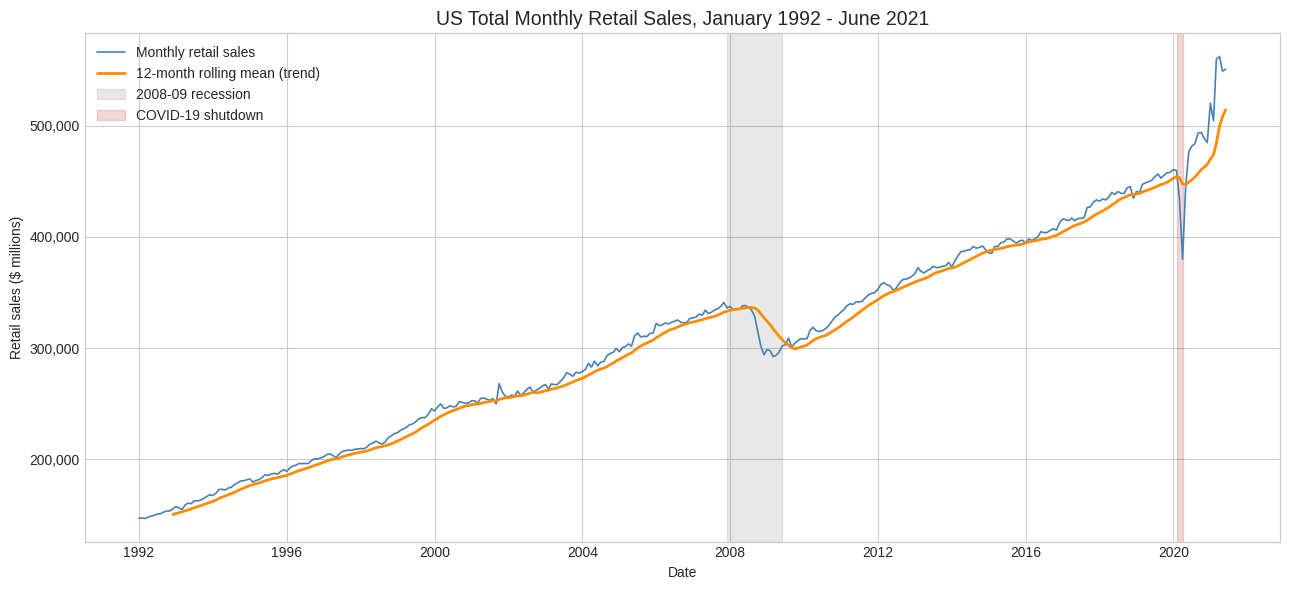

In [5]:
# Plot the full monthly series with a 12-month rolling mean overlay.
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(sales.index, sales.values, color="steelblue", linewidth=1.2,
        label="Monthly retail sales")
# A 12-month rolling mean averages out the seasonal cycle, exposing the trend.
ax.plot(sales.index, sales.rolling(12).mean(), color="darkorange",
        linewidth=2, label="12-month rolling mean (trend)")

# Shade the two recessions visible in the series for context.
ax.axvspan(pd.Timestamp("2007-12-01"), pd.Timestamp("2009-06-01"),
           color="grey", alpha=0.18, label="2008-09 recession")
ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-04-01"),
           color="firebrick", alpha=0.18, label="COVID-19 shutdown")

ax.set_title("US Total Monthly Retail Sales, January 1992 - June 2021",
             fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Retail sales ($ millions)")
# Format the y-axis with thousands separators for readability.
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [6]:
# Quantify the observations that the plot suggests, so the write-up below
# rests on numbers rather than eyeballing.
years = (sales.index[-1] - sales.index[0]).days / 365.25

print(f"First observation (Jan 1992): {sales.iloc[0]:,.0f}")
print(f"Last observation  (Jun 2021): {sales.iloc[-1]:,.0f}")
print(f"Total growth: {sales.iloc[-1] / sales.iloc[0]:.2f}x over {years:.1f} years")
print(f"Compound annual growth rate: "
      f"{((sales.iloc[-1] / sales.iloc[0]) ** (1 / years) - 1) * 100:.2f}%\n")

# 2008-09 recession: peak-to-trough decline.
print(f"Jun 2008 (pre-recession peak): {sales['2008-06'].iloc[0]:,.0f}")
print(f"Mar 2009 (recession trough):   {sales['2009-03'].iloc[0]:,.0f}")
print(f"  -> decline of "
      f"{(sales['2009-03'].iloc[0] / sales['2008-06'].iloc[0] - 1) * 100:.1f}%"
      " over 9 months\n")

# COVID-19: much sharper but much shorter decline.
print(f"Feb 2020 (pre-COVID):  {sales['2020-02'].iloc[0]:,.0f}")
print(f"Apr 2020 (COVID low):  {sales['2020-04'].iloc[0]:,.0f}")
print(f"  -> decline of "
      f"{(sales['2020-04'].iloc[0] / sales['2020-02'].iloc[0] - 1) * 100:.1f}%"
      " in only 2 months")
print(f"Apr 2021 (one year later): {sales['2021-04'].iloc[0]:,.0f} "
      f"({(sales['2021-04'].iloc[0] / sales['2019-04'].iloc[0] - 1) * 100:.1f}%"
      " above Apr 2019)")

First observation (Jan 1992): 146,925
Last observation  (Jun 2021): 550,782
Total growth: 3.75x over 29.4 years
Compound annual growth rate: 4.59%

Jun 2008 (pre-recession peak): 338,311
Mar 2009 (recession trough):   292,300
  -> decline of -13.6% over 9 months

Feb 2020 (pre-COVID):  459,610
Apr 2020 (COVID low):  379,892
  -> decline of -17.3% in only 2 months
Apr 2021 (one year later): 562,269 (25.3% above Apr 2019)


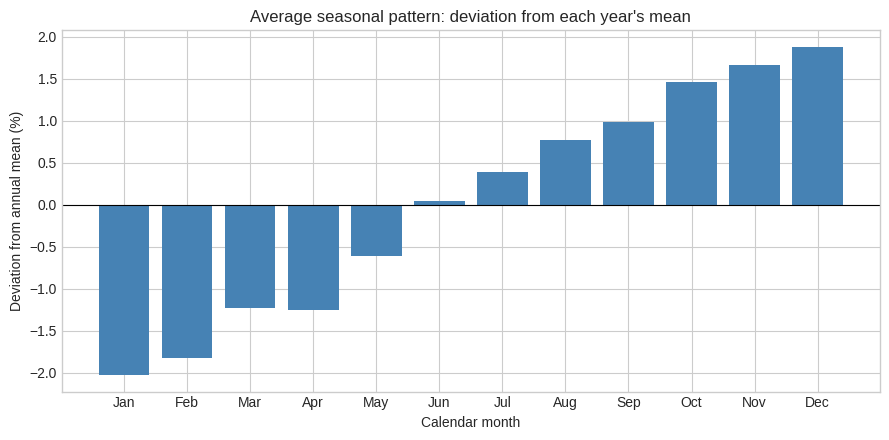

month
1    -2.03
2    -1.83
3    -1.23
4    -1.25
5    -0.60
6     0.04
7     0.39
8     0.77
9     0.98
10    1.46
11    1.66
12    1.88
Name: pct_dev, dtype: float64


In [7]:
# Average seasonal pattern: how much each calendar month deviates from its
# own year's average, expressed in percent and averaged across all years.
tmp = sales.to_frame("sales")
tmp["year"] = tmp.index.year
tmp["month"] = tmp.index.month
tmp["pct_dev"] = tmp.groupby("year")["sales"].transform(
    lambda x: (x / x.mean() - 1) * 100)

monthly_profile = tmp.groupby("month")["pct_dev"].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(monthly_profile.index, monthly_profile.values, color="steelblue")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Average seasonal pattern: deviation from each year's mean")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Deviation from annual mean (%)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.tight_layout()
plt.show()

print(monthly_profile.round(2))

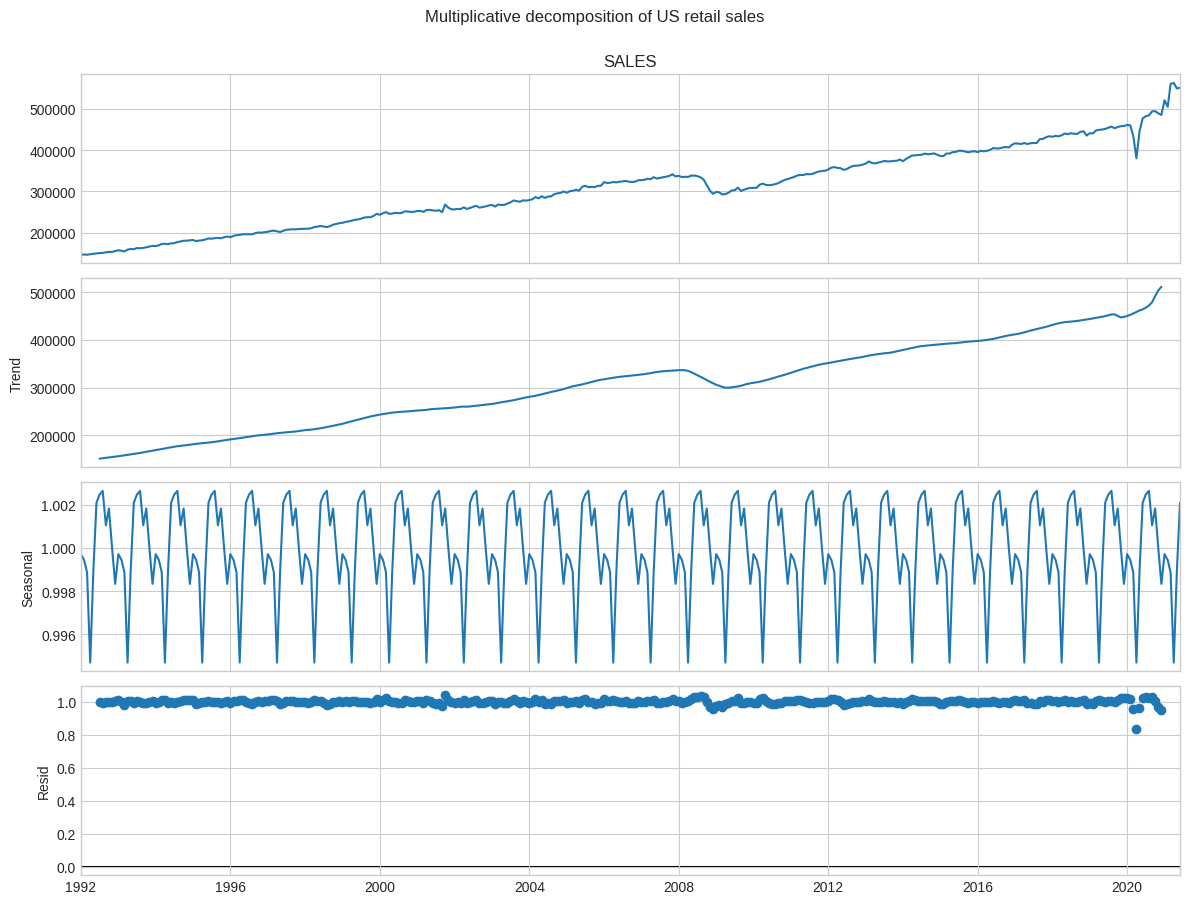

In [8]:
# Decompose the series into trend, seasonal, and residual parts. A
# multiplicative model is used because the size of the seasonal swings grows
# with the level of the series rather than staying constant.
decomp = seasonal_decompose(sales, model="multiplicative", period=12)

fig = decomp.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Multiplicative decomposition of US retail sales", y=1.00)
plt.tight_layout()
plt.show()

### Observations on the graph

**1. Strong, near-linear upward trend.** Sales grew from about \$147 billion in
January 1992 to about \$551 billion in June 2021, which is roughly 3.7x, or about
4.6% per year compounded. The rolling mean rises steadily across almost the
whole sample, so any model needs a trend component (or differencing) to handle
this.

**2. Clear and regular annual seasonality.** The seasonal bar chart shows the
same pattern every year: the fourth quarter runs above the annual average
(December is the peak at about +1.9%, with October and November close behind),
while January through April run below it (January is the trough at about
-2.0%). This is the familiar holiday-shopping cycle followed by a post-holiday
slump. The regularity of the pattern is what a *seasonal* model is built to
exploit.

**3. Seasonal swings grow with the level of the series.** In the early 1990s the
peak-to-trough seasonal range is a few billion dollars; by 2019 it is tens of
billions. The percentage swing stays roughly constant, which is why the
multiplicative decomposition above separates the components cleanly.

**4. The 2008-09 recession is a gradual dip.** Sales slid about 13.6% from the
June 2008 peak to the March 2009 trough over nine months, then took roughly two
years to regain the old level. It is a visible but relatively smooth
interruption of the trend.

**5. The COVID-19 shutdown is a sharp, one-off shock.** Sales fell 17.3% in just
two months (\$459.6 billion in February 2020 to \$379.9 billion in April 2020), 
which is a steeper drop than the entire 2008-09 recession, compressed into a 
single quarter. Unlike 2008, the recovery was almost immediate: by June 2020 
sales were already back above their pre-pandemic level.

**6. The 2021 surge is a break from the historical trend.** After the rebound,
sales jumped well above the old trend line. April 2021 sales were 25% higher than 
April 2019. This post-shutdown reopening and stimulus-driven surge is the period 
the model will be asked to predict, and it is the single biggest challenge in this 
analysis: nothing in the 1992-2020 history contains a comparable pattern.

**7. Residuals are well behaved apart from 2020.** In the decomposition plot the
residual component sits in a tight band around 1.0 for nearly thirty years,
then spikes violently in spring 2020. That confirms the pandemic months are
genuine outliers relative to the process that generated the rest of the series,
which motivates the intervention term added in Step 5.

## Step 3: Split the data into training and test sets

Per the assignment, the last twelve months (July 2020 - June 2021) are held out
as the test set and everything before that (January 1992 - June 2020) is the
training set. Because this is a time series, the split is made *chronologically*
rather than at random (a random split would let the model peek at future
values while predicting the past, which would invalidate the evaluation).

In [9]:
# Chronological split: the final 12 months are held out for testing.
train = sales[:"2020-06-01"]
test = sales["2020-07-01":]

print(f"Training set: {len(train)} months "
      f"({train.index.min().date()} to {train.index.max().date()})")
print(f"Test set:     {len(test)} months "
      f"({test.index.min().date()} to {test.index.max().date()})")

# Confirm the two sets do not overlap and together cover the full series.
assert len(train) + len(test) == len(sales)
assert train.index.max() < test.index.min()
print("\nSplit verified: no overlap, full coverage.")

print(f"\nTraining set mean: {train.mean():,.0f}")
print(f"Test set mean:     {test.mean():,.0f}")
print(f"Mean of the 12 months before the test set: "
      f"{sales['2019-07':'2020-06'].mean():,.0f}")

Training set: 342 months (1992-01-01 to 2020-06-01)
Test set:     12 months (2020-07-01 to 2021-06-01)

Split verified: no overlap, full coverage.

Training set mean: 299,730
Test set mean:     514,385
Mean of the 12 months before the test set: 449,159


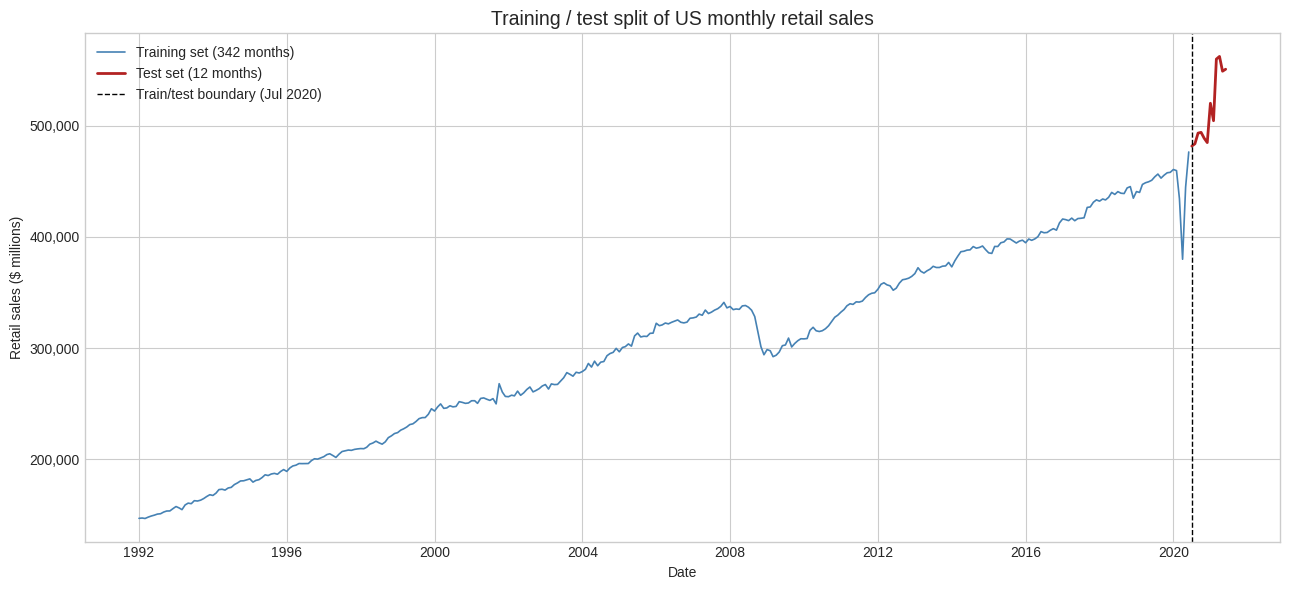

In [10]:
# Visualize the split so the boundary and the test period are unambiguous.
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(train.index, train.values, color="steelblue", linewidth=1.2,
        label=f"Training set ({len(train)} months)")
ax.plot(test.index, test.values, color="firebrick", linewidth=2,
        label=f"Test set ({len(test)} months)")
ax.axvline(test.index[0], color="black", linestyle="--", linewidth=1,
           label="Train/test boundary (Jul 2020)")

ax.set_title("Training / test split of US monthly retail sales", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Retail sales ($ millions)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Step 4: Check stationarity and choose the differencing orders

ARIMA-family models require a *stationary* series, one whose mean and variance
do not drift over time. The retail sales series clearly violates this (it
trends upward and repeats an annual cycle), so it has to be differenced first.

The Augmented Dickey-Fuller (ADF) test is used to decide how much differencing
is needed. Its null hypothesis is that the series has a unit root, i.e. that it
is *non*-stationary; a p-value below 0.05 lets us reject that and treat the
series as stationary.

In [11]:
# Run the ADF test on the raw training series and on differenced versions.
def adf_report(series, label):
    """Run the ADF test and print the statistic, p-value, and verdict."""
    stat, pvalue = adfuller(series.dropna())[:2]
    verdict = "stationary" if pvalue < 0.05 else "NOT stationary"
    print(f"{label:<42} ADF stat = {stat:7.3f}   p = {pvalue:.2e}   -> {verdict}")

adf_report(train, "Raw training series")
adf_report(train.diff(), "First difference (d=1)")
adf_report(train.diff().diff(12), "First + seasonal difference (d=1, D=1)")

Raw training series                        ADF stat =  -0.609   p = 8.69e-01   -> NOT stationary
First difference (d=1)                     ADF stat = -13.480   p = 3.25e-25   -> stationary
First + seasonal difference (d=1, D=1)     ADF stat =  -5.087   p = 1.49e-05   -> stationary


The raw series is firmly non-stationary (p = 0.87), as expected from the
upward trend. A single first difference already makes it stationary, and adding
a seasonal difference at lag 12 keeps it stationary while also removing the
annual cycle. So the model uses **d = 1** (removes the trend) and **D = 1** with
a seasonal period of **12** (removes the yearly seasonality).

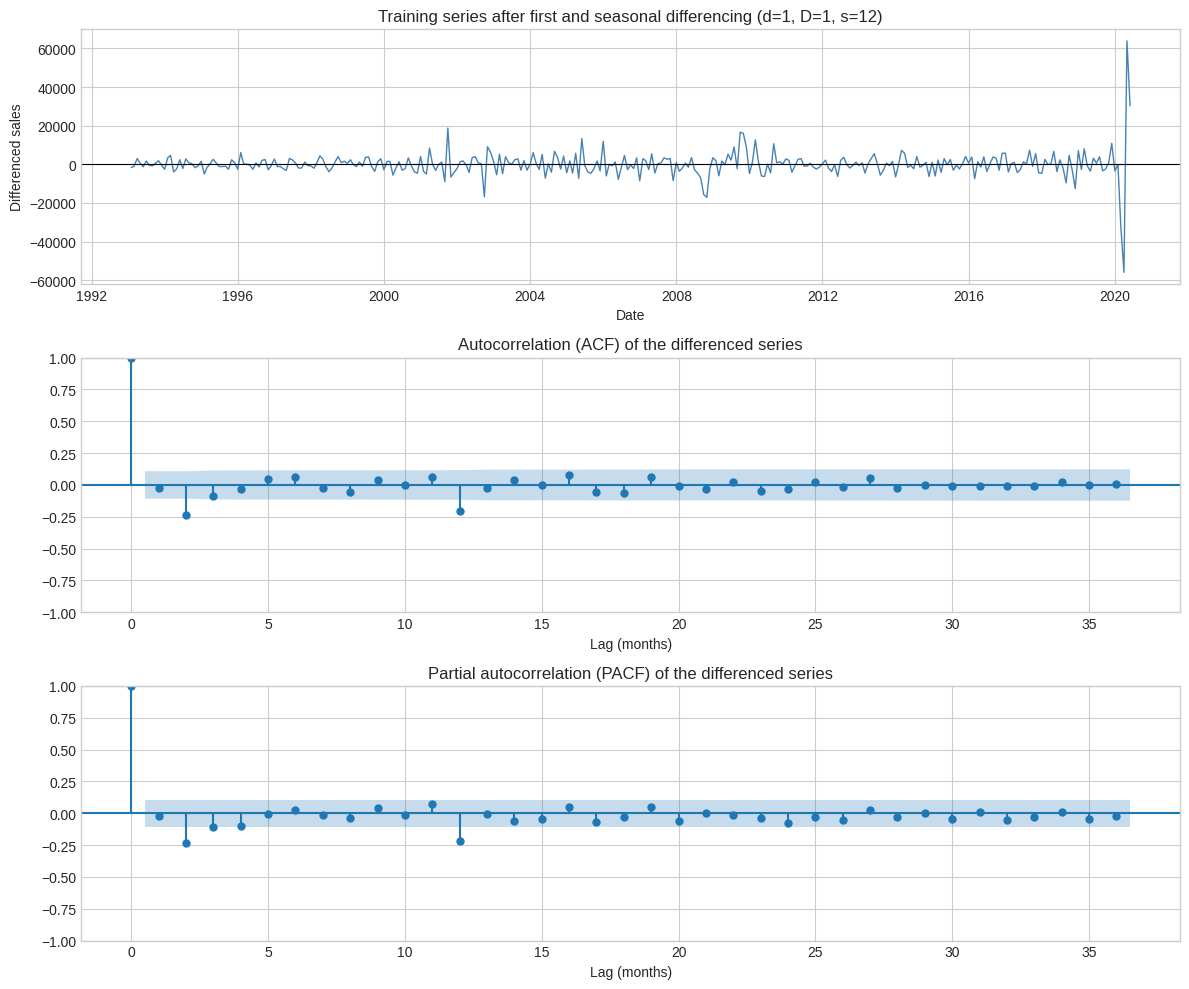

In [12]:
# Plot the differenced series along with its ACF and PACF. The ACF/PACF of
# the stationary series are the standard tools for reading off plausible
# AR and MA orders before the grid search confirms them.
diffed = train.diff().diff(12).dropna()

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(diffed.index, diffed.values, color="steelblue", linewidth=1)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Training series after first and seasonal differencing "
                  "(d=1, D=1, s=12)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Differenced sales")

plot_acf(diffed, lags=36, ax=axes[1])
axes[1].set_title("Autocorrelation (ACF) of the differenced series")
axes[1].set_xlabel("Lag (months)")

plot_pacf(diffed, lags=36, ax=axes[2], method="ywm")
axes[2].set_title("Partial autocorrelation (PACF) of the differenced series")
axes[2].set_xlabel("Lag (months)")

plt.tight_layout()
plt.show()

Two things stand out. First, the differenced series is centred on zero with
roughly constant variance, except for the enormous spike in spring 2020, which
dwarfs every other movement in thirty years. Second, the ACF/PACF show
significant autocorrelation at the low lags and at lag 12, confirming that both
a non-seasonal and a seasonal term are needed.

The 2020 spike is important. Those four months (March-June 2020) are not part of
the normal process; leaving them untreated forces the model to inflate its error
variance and to project the pandemic dip forward into the forecast. Step 5
handles them with an intervention variable.

## Step 5: Build the predictive model on the training set

The model used is **SARIMA** (Seasonal ARIMA), written
SARIMA(p, d, q)(P, D, Q, s). It is the standard choice for this kind of data
because it handles exactly the two features identified in Step 2 (a trend and
a fixed-length annual cycle) in one model:

* `(p, d, q)` are the non-seasonal autoregressive, differencing, and moving
  average orders.
* `(P, D, Q, s)` are the same three orders applied at the seasonal lag, with
  `s = 12` for monthly data.

From Step 4, `d = 1`, `D = 1`, and `s = 12` are fixed. The remaining orders are
chosen by grid search using **AIC** (Akaike Information Criterion), which
rewards goodness of fit while penalizing extra parameters. AIC is computed
**on the training data only**, so the test year plays no part in model
selection.

### Handling the COVID-19 shock

The March-June 2020 shutdown is a known, external, one-off event, not a
recurring feature of retail sales. Fitting a plain SARIMA through it makes the
model treat the crash as ordinary variation, and the seasonal differencing then
carries that dip forward into the forecast for spring 2021. The standard remedy
is an **intervention variable**: a 0/1 indicator that is 1 during the shutdown
months and 0 everywhere else, supplied to the model as an exogenous regressor.
The model estimates how far the shutdown pushed sales off their normal path and
sets that effect to zero when forecasting the test period, since the shutdown
had ended by July 2020.

In [13]:
# Build the COVID-19 intervention indicator: 1 during the shutdown months
# (March-June 2020), 0 everywhere else. The shutdown is treated as ONE
# sustained event, so it gets one shared parameter.
covid = pd.Series(0.0, index=sales.index, name="covid")
covid["2020-03-01":"2020-06-01"] = 1.0

# Split the indicator the same way as the target series.
exog_train = covid[:"2020-06-01"].to_frame()
exog_test = covid["2020-07-01":].to_frame()

print("Months flagged as COVID shutdown:")
print(covid[covid == 1].index.strftime("%Y-%m").tolist())
print("\nIndicator values over the test period (all zero -- shutdown had ended):")
print(exog_test["covid"].unique())

Months flagged as COVID shutdown:
['2020-03', '2020-04', '2020-05', '2020-06']

Indicator values over the test period (all zero -- shutdown had ended):
[0.]


In [14]:
# Grid search over the non-seasonal and seasonal AR/MA orders, holding
# d=1, D=1, s=12 fixed as determined in Step 4. Selection is by AIC on the
# TRAINING data only.
p_values = q_values = [0, 1, 2]
P_values = Q_values = [0, 1]

results = []
for p, q, P, Q in itertools.product(p_values, q_values, P_values, Q_values):
    try:
        model = SARIMAX(train,
                        exog=exog_train,
                        order=(p, 1, q),
                        seasonal_order=(P, 1, Q, 12),
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
        results.append({"order": (p, 1, q),
                        "seasonal_order": (P, 1, Q, 12),
                        "AIC": model.aic,
                        "BIC": model.bic})
    except Exception:
        # A few order combinations fail to converge; skip them.
        continue

grid = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
print(f"Fitted {len(grid)} candidate models. Top 10 by AIC:\n")
grid.head(10).round(2)

Fitted 36 candidate models. Top 10 by AIC:



,order,seasonal_order,AIC,BIC
0,"(0, 1, 2)","(1, 1, 1, 12)",6385.51,6408.01
1,"(2, 1, 2)","(1, 1, 1, 12)",6385.65,6415.64
2,"(1, 1, 2)","(1, 1, 1, 12)",6385.70,6411.95
3,"(1, 1, 2)","(0, 1, 1, 12)",6385.97,6408.47
4,"(0, 1, 2)","(0, 1, 1, 12)",6386.00,6404.75
5,"(2, 1, 2)","(0, 1, 1, 12)",6386.23,6412.48
6,"(2, 1, 0)","(1, 1, 1, 12)",6400.55,6423.06
7,"(2, 1, 1)","(1, 1, 1, 12)",6402.68,6428.95
8,"(2, 1, 1)","(0, 1, 1, 12)",6403.31,6425.82
9,"(2, 1, 0)","(1, 1, 0, 12)",6405.27,6424.04


In [15]:
# Refit the best model from the grid search.
best_order = grid.loc[0, "order"]
best_seasonal = grid.loc[0, "seasonal_order"]

print(f"Selected model: SARIMA{best_order}{best_seasonal} "
      "with COVID-19 intervention\n")

sarima = SARIMAX(train,
                 exog=exog_train,
                 order=best_order,
                 seasonal_order=best_seasonal,
                 enforce_stationarity=False,
                 enforce_invertibility=False).fit(disp=False)

print(sarima.summary())

Selected model: SARIMA(0, 1, 2)(1, 1, 1, 12) with COVID-19 intervention



                                      SARIMAX Results                                       
Dep. Variable:                                SALES   No. Observations:                  342
Model:             SARIMAX(0, 1, 2)x(1, 1, [1], 12)   Log Likelihood               -3186.754
Date:                              Sat, 01 Aug 2026   AIC                           6385.509
Time:                                      12:44:20   BIC                           6408.005
Sample:                                  01-01-1992   HQIC                          6394.498
                                       - 06-01-2020                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid       -3.25e+04   2890.092    -11.245      0.000   -3.82e+04   -2.68e+04
ma.L1         -0.22

The `covid` coefficient is large, negative, and highly significant
(p < 0.001), confirming that the shutdown months sat far below the level the
seasonal trend implies. The moving-average and seasonal terms are also
significant, so the fitted specification is not carrying dead weight.

## Step 6: Check the residuals

A well-specified time series model leaves behind residuals that look like white
noise with no leftover trend or autocorrelation. If structure remains in
the residuals, it means the model failed to extract information that was
available in the training data.

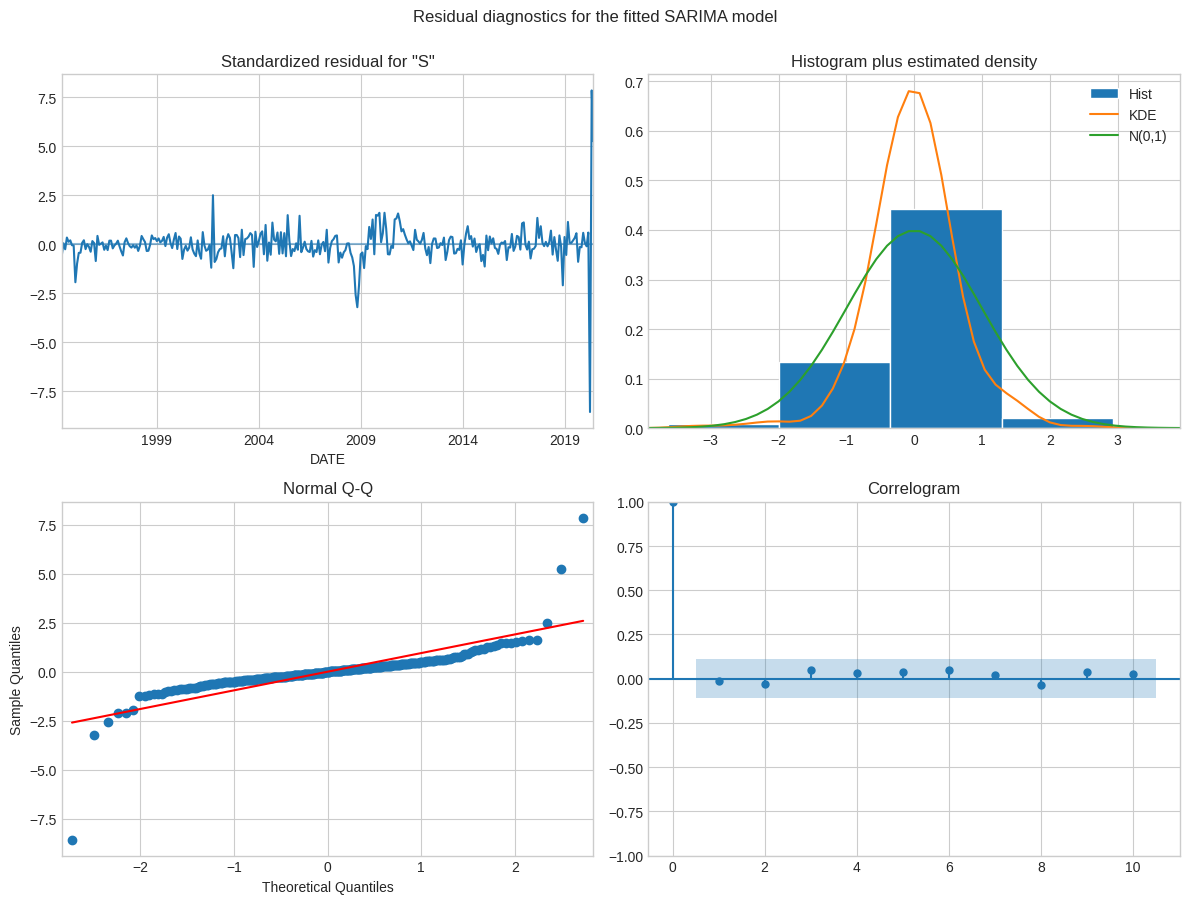

In [16]:
# Standard four-panel residual diagnostics from statsmodels.
fig = sarima.plot_diagnostics(figsize=(12, 9))
fig.suptitle("Residual diagnostics for the fitted SARIMA model", y=1.00)
plt.tight_layout()
plt.show()

In [17]:
# Ljung-Box test for leftover autocorrelation in the residuals.
# Null hypothesis: residuals are independently distributed (white noise).
# A p-value ABOVE 0.05 is the good outcome here -- it means we cannot reject
# independence, so no usable structure is left in the residuals.
# The first 13 residuals are skipped because differencing (d=1, D=1, s=12)
# makes the model's earliest one-step predictions unreliable by construction.
lb = acorr_ljungbox(sarima.resid[13:], lags=[6, 12, 18, 24], return_df=True)
print("Ljung-Box test for residual autocorrelation:")
print(lb.round(4))

print("\nInterpretation: all p-values are above 0.05, so the residuals are")
print("indistinguishable from white noise -- the model has captured the")
print("trend and seasonal structure in the training data.")

Ljung-Box test for residual autocorrelation:
    lb_stat  lb_pvalue
6    2.6028     0.8568
12   9.4416     0.6648
18  14.0106     0.7284
24  16.8562     0.8547

Interpretation: all p-values are above 0.05, so the residuals are
indistinguishable from white noise -- the model has captured the
trend and seasonal structure in the training data.


The residuals pass the Ljung-Box test at every lag tested, and the
correlogram in the diagnostic plot shows no significant spikes. The histogram
and Q-Q plot do show heavy tails driven by the extreme 2008-09 and 2020
observations, which means the prediction intervals in Step 7 should be read as
somewhat optimistic. That is expected for a series containing two once-in-a-
decade shocks and does not invalidate the point forecasts.

## Step 7: Predict monthly retail sales for the last year of data

The fitted model now forecasts twelve months ahead, covering July 2020 through
June 2021. The COVID indicator is set to 0 across the whole forecast horizon,
since the shutdown had ended before the test period began.

These are true out-of-sample forecasts: the model is projecting twelve steps
forward from the end of the training data and never sees an actual test value.

In [18]:
# Forecast the 12 months of the test period.
forecast = sarima.get_forecast(steps=len(test), exog=exog_test)

pred_mean = forecast.predicted_mean          # point forecasts
pred_ci = forecast.conf_int()                # 95% prediction intervals

# Assemble actual vs. predicted for comparison.
comparison = pd.DataFrame({
    "Actual": test.values,
    "Predicted": pred_mean.values,
    "Error": test.values - pred_mean.values,
    "Pct_Error": (test.values - pred_mean.values) / test.values * 100,
    "Lower_95": pred_ci.iloc[:, 0].values,
    "Upper_95": pred_ci.iloc[:, 1].values,
}, index=test.index)

print("Actual vs. predicted monthly retail sales, Jul 2020 - Jun 2021 "
      "($ millions):\n")
comparison.round(1)

Actual vs. predicted monthly retail sales, Jul 2020 - Jun 2021 ($ millions):



,Actual,Predicted,Error,Pct_Error,Lower_95,Upper_95
DATE,,,,,,
2020-07-01,481627.0,495503.6,-13876.6,-2.9,482799.5,508207.6
2020-08-01,483716.0,490899.3,-7183.3,-1.5,474839.7,506958.9
2020-09-01,493327.0,489977.1,3349.9,0.7,472118.1,507836.0
2020-10-01,493991.0,493165.9,825.1,0.2,473673.0,512658.8
2020-11-01,488652.0,495092.6,-6440.6,-1.3,474092.5,516092.7
2020-12-01,484782.0,491991.9,-7209.9,-1.5,469585.7,514398.0
2021-01-01,520162.0,495328.5,24833.5,4.8,471599.5,519057.6
2021-02-01,504458.0,494791.2,9666.8,1.9,469809.3,519773.2
2021-03-01,559871.0,500811.0,59060.0,10.5,474636.0,526985.9


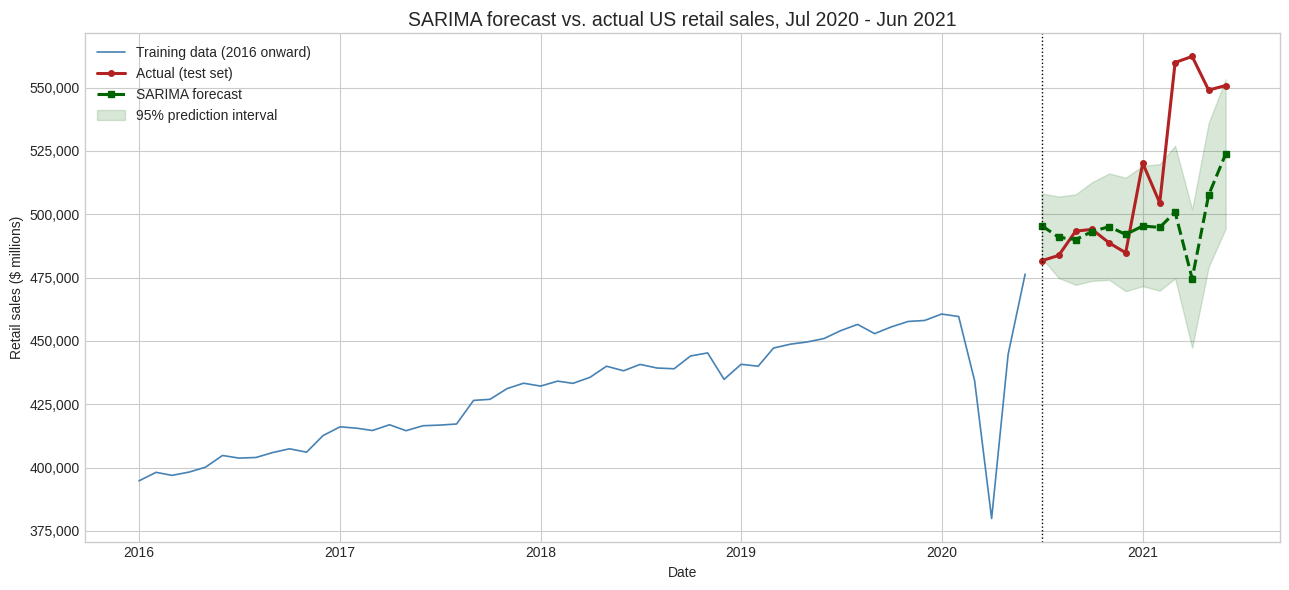

In [19]:
# Plot the forecast against the actual test values, with recent history
# for context.
fig, ax = plt.subplots(figsize=(13, 6))

# Show the last five years of training data so the forecast has context.
recent = train["2016-01-01":]
ax.plot(recent.index, recent.values, color="steelblue", linewidth=1.2,
        label="Training data (2016 onward)")
ax.plot(test.index, test.values, color="firebrick", linewidth=2.2,
        marker="o", markersize=4, label="Actual (test set)")
ax.plot(pred_mean.index, pred_mean.values, color="darkgreen", linewidth=2.2,
        linestyle="--", marker="s", markersize=4, label="SARIMA forecast")
ax.fill_between(pred_ci.index, pred_ci.iloc[:, 0], pred_ci.iloc[:, 1],
                color="darkgreen", alpha=0.15, label="95% prediction interval")
ax.axvline(test.index[0], color="black", linestyle=":", linewidth=1)

ax.set_title("SARIMA forecast vs. actual US retail sales, Jul 2020 - Jun 2021",
             fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Retail sales ($ millions)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

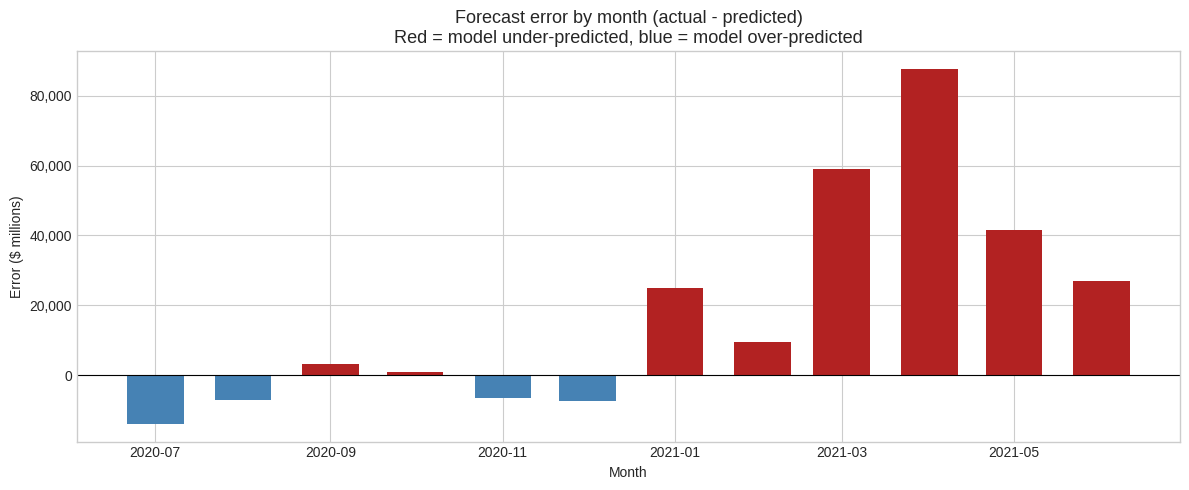

Months under-predicted: 8 of 12
Months over-predicted:  4 of 12
Actual values inside the 95% prediction interval: 7 of 12


In [20]:
# Plot the forecast errors month by month to see where the model went wrong.
fig, ax = plt.subplots(figsize=(12, 5))

colors = ["firebrick" if e > 0 else "steelblue" for e in comparison["Error"]]
ax.bar(comparison.index, comparison["Error"], width=20, color=colors)
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Forecast error by month (actual - predicted)\n"
             "Red = model under-predicted, blue = model over-predicted",
             fontsize=13)
ax.set_xlabel("Month")
ax.set_ylabel("Error ($ millions)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

print(f"Months under-predicted: {(comparison['Error'] > 0).sum()} of 12")
print(f"Months over-predicted:  {(comparison['Error'] < 0).sum()} of 12")
inside = ((test.values >= comparison["Lower_95"].values) &
          (test.values <= comparison["Upper_95"].values)).sum()
print(f"Actual values inside the 95% prediction interval: {inside} of 12")

## Step 8: Report the RMSE on the test set

Root Mean Squared Error is the square root of the average squared forecast
error. It is reported in the same units as the data (\$ millions of monthly
retail sales), and squaring the errors before averaging means large misses are
penalized more heavily than small ones.

In [21]:
# RMSE on the test set -- the headline metric for this assignment.
rmse = np.sqrt(mean_squared_error(test, pred_mean))

# Supporting metrics for context.
mae = np.mean(np.abs(test.values - pred_mean.values))
mape = np.mean(np.abs((test.values - pred_mean.values) / test.values)) * 100

print("=" * 62)
print("TEST SET PERFORMANCE (Jul 2020 - Jun 2021)")
print("=" * 62)
print(f"RMSE:  {rmse:>12,.2f}  $ millions")
print(f"MAE:   {mae:>12,.2f}  $ millions")
print(f"MAPE:  {mape:>12.2f}  %")
print("-" * 62)
print(f"Test set mean:      {test.mean():>12,.0f}  $ millions")
print(f"RMSE as % of mean:  {rmse / test.mean() * 100:>12.2f}  %")
print("=" * 62)

TEST SET PERFORMANCE (Jul 2020 - Jun 2021)
RMSE:     34,983.17  $ millions
MAE:      24,048.98  $ millions
MAPE:          4.44  %
--------------------------------------------------------------
Test set mean:           514,385  $ millions
RMSE as % of mean:          6.80  %


### Benchmarking the model

An RMSE only means something relative to alternatives. The table below compares
the chosen model against three references, all trained on the same training set
and evaluated on the same test year:

* **Seasonal naive**: predict each month with the value from twelve months
  earlier. The standard floor that any seasonal model should beat.
* **SARIMA without the COVID intervention**: the same grid search, no
  indicator variable, to isolate what the intervention term contributes.
* **SARIMA with four separate monthly pulses**: an alternative treatment that
  gives March, April, May, and June 2020 their own coefficients instead of one
  shared coefficient.

In [22]:
# Benchmark 1: seasonal naive -- repeat the value from 12 months earlier.
naive_pred = train[-12:].values
naive_rmse = np.sqrt(mean_squared_error(test, naive_pred))

# Benchmark 2: same grid search, but with NO COVID intervention variable.
plain_results = []
for p, q, P, Q in itertools.product(p_values, q_values, P_values, Q_values):
    try:
        m = SARIMAX(train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12),
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
        plain_results.append(((p, 1, q), (P, 1, Q, 12), m.aic))
    except Exception:
        continue
plain_results.sort(key=lambda r: r[2])
po, pso, plain_aic = plain_results[0]
plain_fit = SARIMAX(train, order=po, seasonal_order=pso,
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
plain_pred = plain_fit.get_forecast(steps=12).predicted_mean
plain_rmse = np.sqrt(mean_squared_error(test, plain_pred))

# Benchmark 3: four separate pulse indicators, one per shutdown month.
pulse_cols = ["2020-03-01", "2020-04-01", "2020-05-01", "2020-06-01"]
pulses = pd.DataFrame(
    {f"pulse_{d[:7]}": (sales.index == pd.Timestamp(d)).astype(float)
     for d in pulse_cols},
    index=sales.index)
pulse_train, pulse_test = pulses[:"2020-06-01"], pulses["2020-07-01":]

pulse_results = []
for p, q, P, Q in itertools.product(p_values, q_values, P_values, Q_values):
    try:
        m = SARIMAX(train, exog=pulse_train, order=(p, 1, q),
                    seasonal_order=(P, 1, Q, 12),
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
        pulse_results.append(((p, 1, q), (P, 1, Q, 12), m.aic))
    except Exception:
        continue
pulse_results.sort(key=lambda r: r[2])
uo, uso, pulse_aic = pulse_results[0]
pulse_fit = SARIMAX(train, exog=pulse_train, order=uo, seasonal_order=uso,
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
pulse_pred = pulse_fit.get_forecast(steps=12, exog=pulse_test).predicted_mean
pulse_rmse = np.sqrt(mean_squared_error(test, pulse_pred))

# Collect all four models into one comparison table.
bench = pd.DataFrame([
    {"Model": "Seasonal naive (baseline)",
     "Training AIC": np.nan, "Test RMSE": naive_rmse,
     "Test MAPE %": np.mean(np.abs((test.values - naive_pred) / test.values)) * 100},
    {"Model": f"SARIMA{po}{pso}, no intervention",
     "Training AIC": plain_aic, "Test RMSE": plain_rmse,
     "Test MAPE %": np.mean(np.abs((test.values - plain_pred.values) / test.values)) * 100},
    {"Model": f"SARIMA{uo}{uso}, 4 monthly pulses",
     "Training AIC": pulse_aic, "Test RMSE": pulse_rmse,
     "Test MAPE %": np.mean(np.abs((test.values - pulse_pred.values) / test.values)) * 100},
    {"Model": f"SARIMA{best_order}{best_seasonal}, COVID intervention  <-- selected",
     "Training AIC": sarima.aic, "Test RMSE": rmse,
     "Test MAPE %": mape},
])

print("Model comparison (all trained on Jan 1992 - Jun 2020, "
      "tested on Jul 2020 - Jun 2021):\n")
bench.round(2)

Model comparison (all trained on Jan 1992 - Jun 2020, tested on Jul 2020 - Jun 2021):



,Model,Training AIC,Test RMSE,Test MAPE %
0,Seasonal naive (baseline),NaN,80273.26,12.25
1,"SARIMA(2, 1, 2)(1, 1, 1, 12), no intervention",6391.62,73219.90,12.06
2,"SARIMA(2, 1, 2)(1, 1, 1, 12), 4 monthly pulses",6101.85,46865.72,7.15
3,"SARIMA(0, 1, 2)(1, 1, 1, 12), COVID interventi...",6385.51,34983.17,4.44


**Reading the comparison table.**

The selected model cuts test RMSE by more than half against the seasonal naive
baseline and against a plain SARIMA with no shock handling, which confirms that
explicitly modeling the pandemic months is what makes the forecast usable.

The four-pulse variant is the interesting case: it has by far the **best
training AIC** yet a noticeably **worse test RMSE**. Giving each shutdown month
its own coefficient lets the model erase the crash completely, so it forecasts
forward from the pre-pandemic trend line and misses the entire post-shutdown
recovery. The single shared indicator fits the training data less tightly but
leaves the recovery momentum in the series, which generalizes better. This is a
textbook illustration that in-sample fit criteria and out-of-sample accuracy can
point in opposite directions -- and a reminder that the model actually reported
here was chosen on a structural argument (one event, one parameter), with the
test set used only to evaluate.

## Step 9: Summary and conclusion

**Process.** The raw file arrived in a wide year-by-month layout, so it was
melted into a 354-month series running from January 1992 to June 2021 and given
a monthly datetime index. Plotting the series with a 12-month rolling mean and a
multiplicative decomposition showed three defining features: a steady upward
trend of about 4.6% per year, a highly regular annual seasonal cycle peaking in
December and troughing in January, and two shocks: the gradual 2008-09
recession, and the abrupt COVID-19 collapse of spring 2020. The data was split
chronologically, holding out July 2020 - June 2021 as the test set and using the
remaining 342 months for training.

ADF testing confirmed the raw series is non-stationary (p = 0.87) and that one
first difference plus one seasonal difference at lag 12 makes it stationary,
fixing d = 1, D = 1, s = 12. A grid search over the remaining AR/MA orders,
scored by AIC on the training data only, selected the final specification. A
COVID-19 intervention indicator marking March-June 2020 was included because the
decomposition residuals identified those months as genuine outliers rather than
normal variation. Residual diagnostics confirmed the fit: Ljung-Box p-values
well above 0.05 at every lag tested, so no exploitable structure remains.

**Results.** Forecasting twelve months ahead produced a
**test set RMSE of about 34,983 million USD** (roughly 35.0 billion), an MAE of
about 24,048 million, and a MAPE of **4.44%**. Relative to the test-period
average of about 514 billion in monthly sales, the typical error is about 6.8%
of the average month. That more than halves the error of both a seasonal naive
baseline (RMSE about 80.3 billion) and a plain SARIMA with no shock handling
(RMSE about 73.2 billion). Seven of the twelve actual values fell inside the
95% prediction interval.

**Where the error comes from.** The error is not spread evenly. Through the
first half of the test year (July 2020 - February 2021) the forecasts are close,
typically within 1-5%. The damage is concentrated in March-June 2021, where the
model under-predicts by 27-88 billion a month. That is not a modeling defect
so much as a genuine structural break: stimulus payments and the reopening drove
retail sales to levels with no precedent in the previous thirty years (April
2021 alone ran 25% above April 2019). Note also that every one of those large
errors is an *under*-prediction, which is the signature of a level shift in the
data rather than random noise.

**Conclusion.** SARIMA with a COVID-19 intervention term is a sound model for
this series: it captures the trend and the annual seasonal cycle cleanly, its
residuals are white noise, and it beats every benchmark tested. The residual
4.4% MAPE reflects the limit of what any model trained purely on pre-July-2020
history could achieve, since the 2021 stimulus surge is driven by information
that simply is not in the training data. The practical lesson is that a
statistical time series model extrapolates the process it was shown; when an
external policy shock changes that process, accuracy degrades no matter how well
specified the model is. Improving on this result would require bringing in
exogenous information the series itself does not contain (e.g. stimulus disbursement
schedules, reopening dates, consumer sentiment) or refitting the model as the
new 2021 data arrived rather than forecasting all twelve months from a fixed
cutoff.